# Student Performance Prediction
## [Educational] Multiple Linear Regression Project

# Case Study: Analyzing Data Leakage in Synthetic Regression Models
**Author:** Fotini Tassia

### Project Core Focus
"The main goal of this project was to demonstrate how deduplication impacts model metrics via row memorization."

### Key Findings
* **The Vulnerability:** Discovered **127 duplicate rows** introduced during the synthetic data generation process.
* **The Leakage:** Prior to deduplication, the `train_test_split` allowed identical rows into both the training and testing sets, artificially inflating model metrics through memorization.
* **The Outcome:** Removing duplicate rows led to a minor drop in the final \(R^2\) score but established a statistically honest, reliable evaluation baseline.


In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
import glob
csv_files = glob.glob("../input/**/Student_Performance.csv", recursive=True)
if csv_files:
    df = pd.read_csv(csv_files[0])
    print("Dataset loaded successfully!")
else:
    print("CSV file not found. Please ensure the dataset is added to your notebook.")


Dataset loaded successfully!


In [3]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     10000 non-null  int64  
 1   Previous Scores                   10000 non-null  int64  
 2   Extracurricular Activities        10000 non-null  object 
 3   Sleep Hours                       10000 non-null  int64  
 4   Sample Question Papers Practiced  10000 non-null  int64  
 5   Performance Index                 10000 non-null  float64
dtypes: float64(1), int64(4), object(1)
memory usage: 468.9+ KB
None


In [4]:
print(df.head(5))

   Hours Studied  Previous Scores Extracurricular Activities  Sleep Hours  \
0              7               99                        Yes            9   
1              4               82                         No            4   
2              8               51                        Yes            7   
3              5               52                        Yes            5   
4              7               75                         No            8   

   Sample Question Papers Practiced  Performance Index  
0                                 1               91.0  
1                                 2               65.0  
2                                 2               45.0  
3                                 2               36.0  
4                                 5               66.0  


In [5]:
print(df.isna().sum())

Hours Studied                       0
Previous Scores                     0
Extracurricular Activities          0
Sleep Hours                         0
Sample Question Papers Practiced    0
Performance Index                   0
dtype: int64


In [6]:
print(df.describe())

       Hours Studied  Previous Scores   Sleep Hours  \
count   10000.000000     10000.000000  10000.000000   
mean        4.992900        69.445700      6.530600   
std         2.589309        17.343152      1.695863   
min         1.000000        40.000000      4.000000   
25%         3.000000        54.000000      5.000000   
50%         5.000000        69.000000      7.000000   
75%         7.000000        85.000000      8.000000   
max         9.000000        99.000000      9.000000   

       Sample Question Papers Practiced  Performance Index  
count                      10000.000000       10000.000000  
mean                           4.583300          55.224800  
std                            2.867348          19.212558  
min                            0.000000          10.000000  
25%                            2.000000          40.000000  
50%                            5.000000          55.000000  
75%                            7.000000          71.000000  
max             

In [7]:
Activities = {'Yes': 1, 'No': 0}
df["Extracurricular Activities"] = df["Extracurricular Activities"].map(Activities)

In [8]:
print(df.head(5))

   Hours Studied  Previous Scores  Extracurricular Activities  Sleep Hours  \
0              7               99                           1            9   
1              4               82                           0            4   
2              8               51                           1            7   
3              5               52                           1            5   
4              7               75                           0            8   

   Sample Question Papers Practiced  Performance Index  
0                                 1               91.0  
1                                 2               65.0  
2                                 2               45.0  
3                                 2               36.0  
4                                 5               66.0  


In [9]:
#With duplicates
X_org = df.drop(columns=["Performance Index"])
y_org = df["Performance Index"]

In [10]:
X_org_train, X_org_test, y_org_train, y_org_test = train_test_split(X_org, y_org, test_size=0.2, random_state = 42)

In [11]:
model_org = LinearRegression()

In [12]:
model_org.fit(X_org_train, y_org_train)

LinearRegression()

In [13]:
y_org_pred = model_org.predict(X_org_test)

In [14]:
r2_org = r2_score(y_org_test, y_org_pred)
mae_org = mean_absolute_error(y_org_test, y_org_pred)
mse_org = mean_squared_error(y_org_test, y_org_pred)

In [15]:
print(f"R sqarred: {r2_org:.4f}")
print(f"Mean Absolute Error: {mae_org:.4f}")
print(f"Mean Squarred Error: {mse_org:.4f}")

R sqarred: 0.9890
Mean Absolute Error: 1.6111
Mean Squarred Error: 4.0826


In [16]:
for col, coef in zip(X_org.columns, model_org.coef_):
    print(f"column: {col}, coefficient: {coef}")

column: Hours Studied, coefficient: 2.8524839300725775
column: Previous Scores, coefficient: 1.016988198932932
column: Extracurricular Activities, coefficient: 0.60861667957642
column: Sleep Hours, coefficient: 0.4769414841762728
column: Sample Question Papers Practiced, coefficient: 0.19183144145054246


In [17]:
duplicate_count = df.duplicated().sum()
print(f"Number of duplicate rows found: {duplicate_count}")

Number of duplicate rows found: 127


In [18]:
if duplicate_count > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print("Duplicates successfully removed!")

Duplicates successfully removed!


In [19]:
X = df.drop(columns=["Performance Index"])
y = df["Performance Index"]

In [20]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state = 42)

In [21]:
model = LinearRegression()

In [22]:
model.fit(X_train, y_train)

LinearRegression()

In [23]:
y_pred = model.predict(X_test)

In [24]:
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)

In [25]:
print(f"R sqarred: {r2:.4f}")
print(f"Mean Absolute Error: {mae:.4f}")
print(f"Mean Squarred Error: {mse:.4f}")

R sqarred: 0.9884
Mean Absolute Error: 1.6470
Mean Squarred Error: 4.3059


In [26]:
for col, coef in zip(X.columns, model.coef_):
    print(f"column: {col}, coefficient: {coef}")

column: Hours Studied, coefficient: 2.851021897391882
column: Previous Scores, coefficient: 1.018430343479819
column: Extracurricular Activities, coefficient: 0.5738229675498986
column: Sleep Hours, coefficient: 0.4720732934093176
column: Sample Question Papers Practiced, coefficient: 0.18870365910309272


In [27]:
print(f"R sqarred: without deduplication: {r2_org:.4f}, after deduplication: {r2:.4f}")
print(f"Mean Absolute Error without deduplication: {mae_org:.4f},  after deduplication: {mae:.4f}")
print(f"Mean Squarred Error without deduplication: {mse_org:.4f}, after deduplication: {mse:.4f}")


R sqarred: without deduplication: 0.9890, after deduplication: 0.9884
Mean Absolute Error without deduplication: 1.6111,  after deduplication: 1.6470
Mean Squarred Error without deduplication: 4.0826, after deduplication: 4.3059


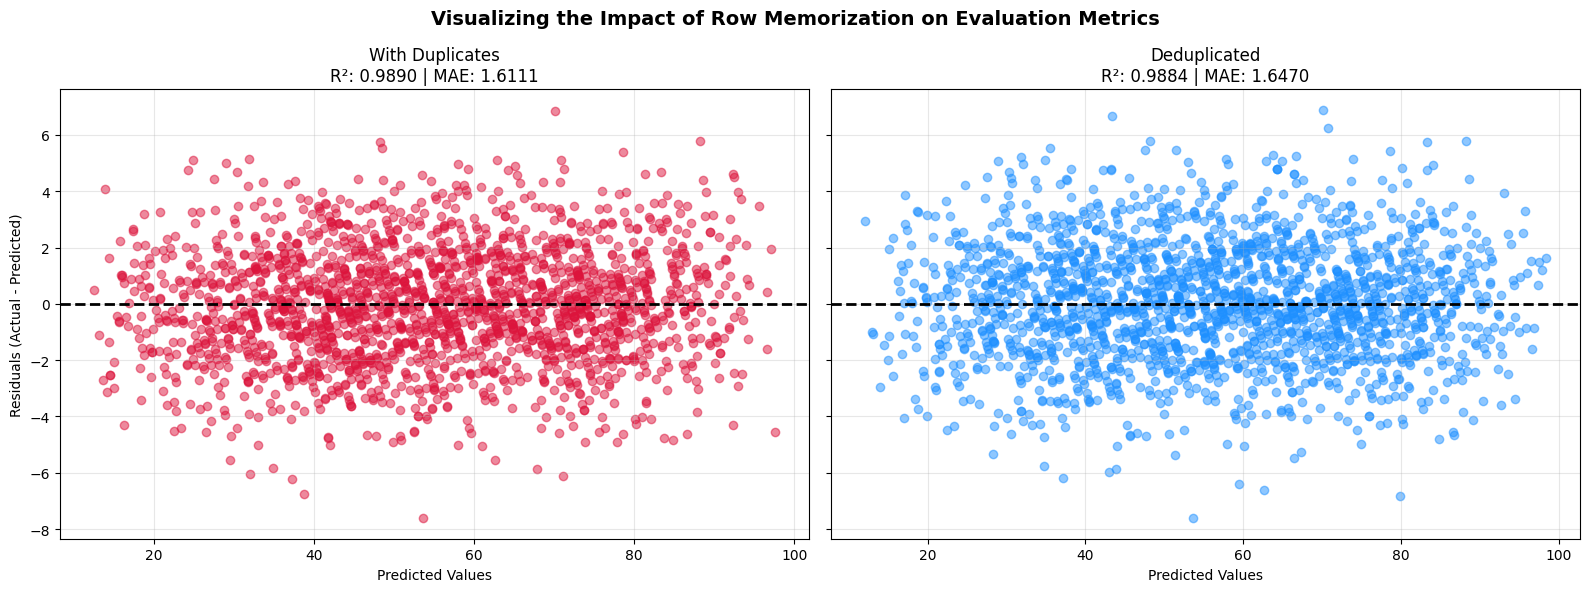

In [32]:
residuals_org = y_org_test - y_org_pred
residuals = y_test - y_pred
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
axes[0].scatter(y_org_pred, residuals_org, alpha=0.5, color="crimson")
axes[0].axhline(y=0, color="black", linestyle="--", linewidth=2)
axes[0].set_title(
    f"With Duplicates\nR²: {r2_org:.4f} | MAE: {mae_org:.4f}"
)
axes[0].set_xlabel("Predicted Values")
axes[0].set_ylabel("Residuals (Actual - Predicted)")
axes[0].grid(True, alpha=0.3)

axes[1].scatter(y_pred, residuals, alpha=0.5, color="dodgerblue")
axes[1].axhline(y=0, color="black", linestyle="--", linewidth=2)
axes[1].set_title(
    f"Deduplicated\nR²: {r2:.4f} | MAE: {mae:.4f}"
)
axes[1].set_xlabel("Predicted Values")
axes[1].grid(True, alpha=0.3)

plt.suptitle(
    "Visualizing the Impact of Row Memorization on Evaluation Metrics",
    fontsize=14,
    weight="bold",
)
plt.tight_layout()
plt.show()
